# The space of floating point numbers

(Theory in scientific computing)

- To understand how computers store the data
- What kind of structure we ise to store, manipulate and do math with data.
- To understand the limitation of floating point numbers.

**Issue:** In mathematics $x\in (-\infty, \infty)$, there are infinitely many numbers. So we cannot store them all inside the finite memory!

**Definition:** LEt $e_{min}, e_{max}$ be fixed integers (exponents). Fix $p\in\mathbb{N}$ (the number of significands).

Define
$$
\mathcal{F} = \{ x = 0,\ \text{or}\ x = \pm \, m\cdot 2^e \ | \ e_{min} \le e \le e_{max} \},
$$
where $m$ is a binary number (mantissa) of $p$ digits.

- $\mathcal{F}$ is a finite set of real numbers.
- What is the form of the mantissa $m$?

$$
m = (1.b_1b_2\ldots b_{m-1})_2
$$
as a number in base 2 (binary format)

## Binary Representation of integers

$$
n = (a_m a_{m-1} \ldots a_0)_2 = a_m * 2^m + a_{m-1} * 2^{m-1} + \cdots + a_1 * 2 + a_0
$$

Given $n$, write a function to represent $n$ as binary.

In [1]:
from mpmath import diff


def binary_form(n):
    digits = []
    while n != 0:
        r = n % 2
        n = n // 2
        digits.append(r)
    # reverse the order of digits to get the right binary
    return digits[::-1]

In [2]:
binary_form(10)

[1, 0, 1, 0]

In [3]:
# concatenate strings in Python
l = ["a", "b", "c", "d"]

In [4]:
print("*".join(l))

a*b*c*d


In [5]:
print(" ".join(l))

a b c d


In [6]:
print("_".join(l))

a_b_c_d


In [7]:
def binary_form(n):
    digits = []
    while n != 0:
        r = n % 2
        n = n // 2
        digits.append(r)
    # reverse the order of digits to get the right binary
    # return a string to represent the binary form
    digits = digits[::-1]
    digits = [str(i) for i in digits]
    binary_string = "".join(digits)
    return f"({binary_string})_2"

In [8]:
binary_form(101)

'(1100101)_2'

In [9]:
# quick answer
format(101, "b")

'1100101'

**Example:** Write a function to represent a real number, $r\in (0, 1)$ in binary form with given precision $p=5$.

In [10]:
def frac_to_binary(r, p=5):
    digits = []
    for i in range(p):
        b = int(2 * r)
        digits.append(b)
        r = 2 * r - b

    digits = [str(i) for i in digits]
    binary_string = "".join(digits)

    return f"(0.{binary_string})_2"

In [11]:
r = 0.625
frac_to_binary(r)

'(0.10100)_2'

In [12]:
frac_to_binary(0.3)

'(0.01001)_2'

In [13]:
frac_to_binary(0.3, p=53)

'(0.01001100110011001100110011001100110011001100110011001)_2'

In [14]:
0.1 + 0.2 == 0.3

False

## How to represent any real numbers as `machine numbers`.

Recall floating point numbers

$$
\mathbb{F}(2, p, e_{min}, e_{max}) = \{0\} \cup \{x = \pm m *2^e\ :\ e_{\min}\le e \le e_{max}\}
$$
where $m$ is the mantissa, $p$ is the precision (number of significands).

**Example:** List all the machine numbers in the system
$$
\mathbb{F}(2, 5, -1, 3)
$$

We have $p=5$, $-1 \le e \le 3.$ The mantissa has the form
$$
m = (1.b_1b_2b_3b_4)_2
$$

All possible mantisa numbers:
$$
m = (1.0000)_2; (1.0001)_2; (1.0010)_2; (1.0011)_2; \ldots; (1.1111)_2
$$
There are $2^4=16$ numbers from $1.0000$ to $(1.1111)$

The maximum value is $2^3*(1.1111)_2 = 2^3*(1 + 1/2 + 1/4 + 1/8 + 1/16) = 15.5$

In [15]:
2**3 *(1+ 1/2 + 1/4 + 1/8 + 1/16)

15.5

If $x = 3^4*(1.1111)_2$ is not inside $\mathbb{F}$. Actually $x = 3^4*(1.1111)_2 = \infty$.

## Approximate real numbers by floating point numbers

**Theorem:** For any $x \in (-\infty, \infty)$, there exists a `machine number`, denoted by $fl(x) \in \mathbb{F}$ such that
$$
\frac{fl(x) - x}{x} \lt \epsilon,
$$
where $\epsilon$ = $2^{1-p}$ is the machine epsilon.

**Example:** Write a function to list all the values in $F(2, p, e_{min}, e_{max})$.

$x = 2^e(1.b_1\ldots b_{p-1})_2$ where the mantissa
$$
m = ((1.b_1\ldots b_{p-1})
$$ satisfies
$$
1 \le m \le (1.1\ldots 1)_2 = 1 + \frac{1}{2} + \cdots + \frac{1}{2^{p-1}} = 2 - 2^{1-p}
$$

In [16]:
import numpy as np

In [17]:
def f_space(p, emin, emax):
    mantissa = (2**(p-1) + np.arange(2**(p-1))) / (2**(p-1))
    pos_float = []
    for e in range(emin, emax+1):
        for m in mantissa:
            pos_float.append(2**e*m)

    # merge 2 arrays: neg float, [0], pos_float
    results = [-1.0 * v for v in pos_float[::-1]]
    results.append(0.0)
    results.extend(pos_float)
    return np.array(results)

In [18]:
# test is
p = 5
emin = -1
emax = 3

In [19]:
f_space(p, emin, emax)

array([-15.5    , -15.     , -14.5    , -14.     , -13.5    , -13.     ,
       -12.5    , -12.     , -11.5    , -11.     , -10.5    , -10.     ,
        -9.5    ,  -9.     ,  -8.5    ,  -8.     ,  -7.75   ,  -7.5    ,
        -7.25   ,  -7.     ,  -6.75   ,  -6.5    ,  -6.25   ,  -6.     ,
        -5.75   ,  -5.5    ,  -5.25   ,  -5.     ,  -4.75   ,  -4.5    ,
        -4.25   ,  -4.     ,  -3.875  ,  -3.75   ,  -3.625  ,  -3.5    ,
        -3.375  ,  -3.25   ,  -3.125  ,  -3.     ,  -2.875  ,  -2.75   ,
        -2.625  ,  -2.5    ,  -2.375  ,  -2.25   ,  -2.125  ,  -2.     ,
        -1.9375 ,  -1.875  ,  -1.8125 ,  -1.75   ,  -1.6875 ,  -1.625  ,
        -1.5625 ,  -1.5    ,  -1.4375 ,  -1.375  ,  -1.3125 ,  -1.25   ,
        -1.1875 ,  -1.125  ,  -1.0625 ,  -1.     ,  -0.96875,  -0.9375 ,
        -0.90625,  -0.875  ,  -0.84375,  -0.8125 ,  -0.78125,  -0.75   ,
        -0.71875,  -0.6875 ,  -0.65625,  -0.625  ,  -0.59375,  -0.5625 ,
        -0.53125,  -0.5    ,   0.     ,   0.5    , 

**Example:** Write a function to find the floating point representation of any $x$ value.

In [21]:
x = 14.123

In [22]:
import math

`math.frexp(x)` returns $2^e*m$ where $0.5 \le m \lt 1$

In [26]:
frac, exp = math.frexp(x)

In [27]:
print(frac, exp)

0.8826875 4


In [25]:
2**4*(0.8826875) == 2**3*(0.8826875*2)

True

In [28]:
e = exp - 1
m = 2 * frac

In [29]:
2**e*m

14.123

In [30]:
print(m)

1.765375


In [31]:
m_scaled = int(2**4*m)

In [32]:
print(m_scaled)

28


Convert 28 into binary form

In [33]:
format(28, "b")

'11100'

Floating point representation of x = 14.123 is
$$
14.123 = 2^3(1.1100)_2.
$$

What is the actual value for $2^3(1.1100)_2$? and how far is it from $x=14.123$?

In [34]:
2**3*(1 + 1/2 + 1/4)

14.0

Question: Given $p$, emin, emax, write a function to return the value of floating representation of $x$ in the space $F(2, p, e_{min}, e_{max})$

For example, in $F(p=5, emin=-1, emax=3)$ the $fl(x=14.123) = 2^3*(1.1100) = 8 * 1.75 = 14$

$x = 2^e+m$, but $1 \le m \lt 2$. So
$$
2^e \le x \lt 2^{e+1}
$$

$$
e \le \log_2(x) < e + 1
$$

This means $e = int(\log_2(x))$.

In [3]:
import math

In [4]:
# compare floor and int
print(math.floor(1.23))
print(math.floor(-1.23))
print(int(1.23))
print(int(-1.23))

1
-2
1
-1


In [35]:
def fl(x, p, emin, emax):
    if x == 0:
        return 0
    sign = 1.0 if x > 0 else -1.0
    x = abs(x)
    # compute the exponent e
    e = math.floor(math.log2(x))
    # compute the mantissa
    m = x / 2**e
    # scale up the mantissa so that we can get an integer
    m_scaled = m * 2**(p-1)
    # round the scaled m
    m_rounded = round(m_scaled)

    # if x is too small, we set it to be zero!
    if e < emin:
        return sign * 0.0 # underflow
    result = m_rounded * 2**(e-p+1)
    # if the result > max value in the space, we set infinity
    if result > (2 - 2**(1-p)) * 2**emax:
        return sign * math.inf
    else:
        return sign * result

In [36]:
x = 14.123
p = 5
emin = -1
emax = 3

In [37]:
fl(x, p, emin, emax)

14.0

In [38]:
fl(30, p, emin, emax)

inf

**Theorem:** For any real number $x$, we have $fl(x) \in F(2, p, e_{min}, e_{max})$. Set $u=2^{-p}$ to be the rounding unit. Then we have
$$
\big | \frac{fl(x) - x}{x} \big | < u
$$
It means the relative errpr between $fl(x)$ and $x$ is small.

**Example:** Use Python to show the above theorem.

In [39]:
p = 10
emin = -8
emax = 8

In [40]:
# rounding unit
u = 2**(-p)

In [41]:
import numpy as np
import matplotlib.pyplot as plt

In [55]:
x = np.linspace(-5, 5, 1000)

In [56]:
# compute all floating pt representations
x_fl = [fl(x, p, emin, emax) for x in x]
x_fl[300:310]

[-1.99609375,
 -1.986328125,
 -1.9765625,
 -1.966796875,
 -1.95703125,
 -1.947265625,
 -1.9375,
 -1.927734375,
 -1.916015625,
 -1.90625]

In [57]:
# compute the relative error
# |(fl(x) - x ) / x|
rel_err = [
    (u - v) / v for u, v in zip(x_fl, x)
]

In [58]:
rel_err[:10]

[np.float64(-0.0),
 np.float64(0.0004403836509528579),
 np.float64(-0.0006862437185929663),
 np.float64(-0.0002454682779456215),
 np.float64(0.0001970862764883927),
 np.float64(0.0006414307381193089),
 np.float64(-0.0004939209726443812),
 np.float64(-4.917512690355835e-05),
 np.float64(0.0003973804679552333),
 np.float64(-0.0007454128440367038)]

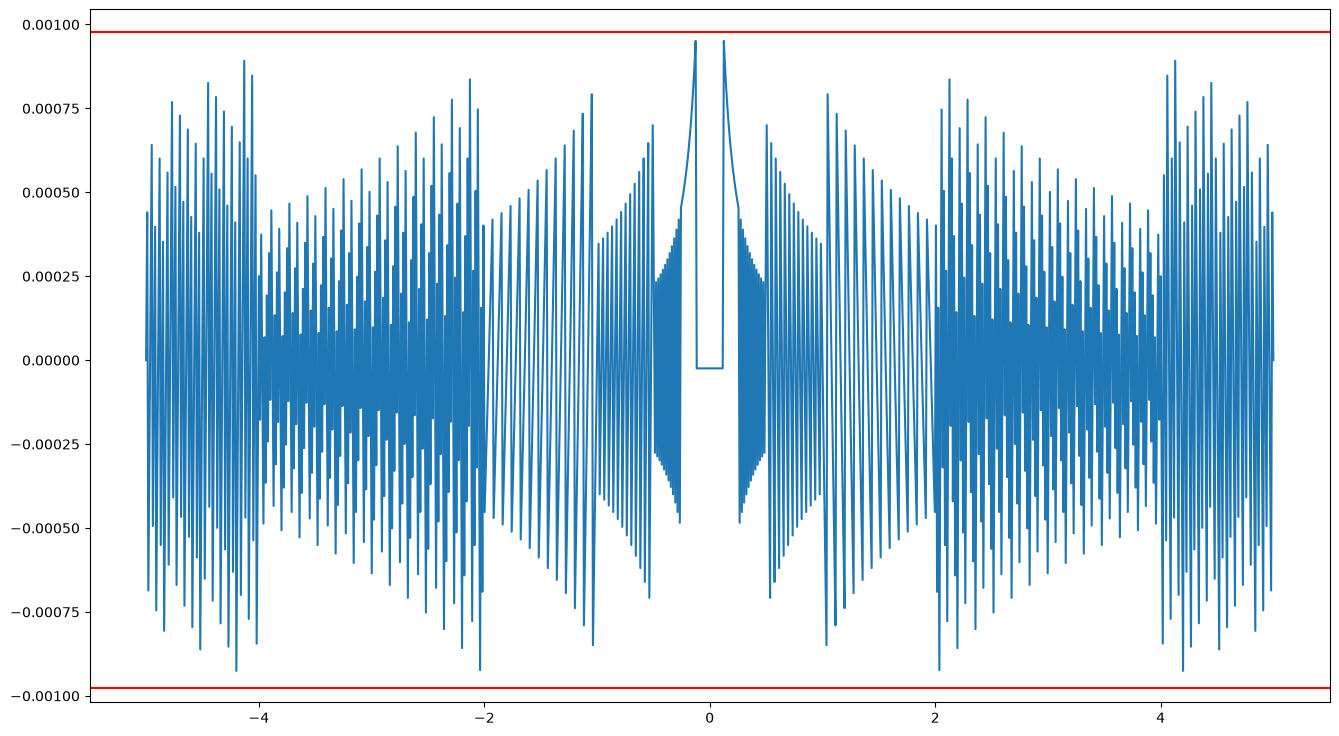

In [60]:
# plot the rel_err
fig, ax = plt.subplots(figsize=(16, 9))
ax.plot(x, rel_err, label="relative error")

# show the bands
ax.axhline(u, color="r")
ax.axhline(-u, color="r")

plt.show()

Based on the plot, the relative error varies in between $-u$ and $u$. This verifies the theorem.

## The Error analysis

In floating point space, adding two positive values is exact (adding as small error). However, subtracting two positive values that have about the same magnitudes, then they will cancel out the significant digits so the subtraction may yield a zero with large error. This is called the cancellation error.

**Example:** Do the error analysis for the function

$$
f(X) = \sqrt{x+1} - \sqrt{x}
$$
where $x$ is the very large value.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# create a list of values
# 10^0, 10^1, ..., 10^{32}
# use np.logspace(start_power, end_power, number_of_points)
xs = np.logspace(0, 32, 500)

In [5]:
# define the naive function
def f_naive(x):
    return math.sqrt(x + 1) - math.sqrt(x)

In [6]:
# compute the values of f(x) where x in xs
ys = [f_naive(x) for x in xs]

In [9]:
ys[-10:]

[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

Based on the result, the last 10 values of the function $f(x)$ are zeros! This is impossible as $f(x) \ne 0$.
Let's plot the function and visualize it.

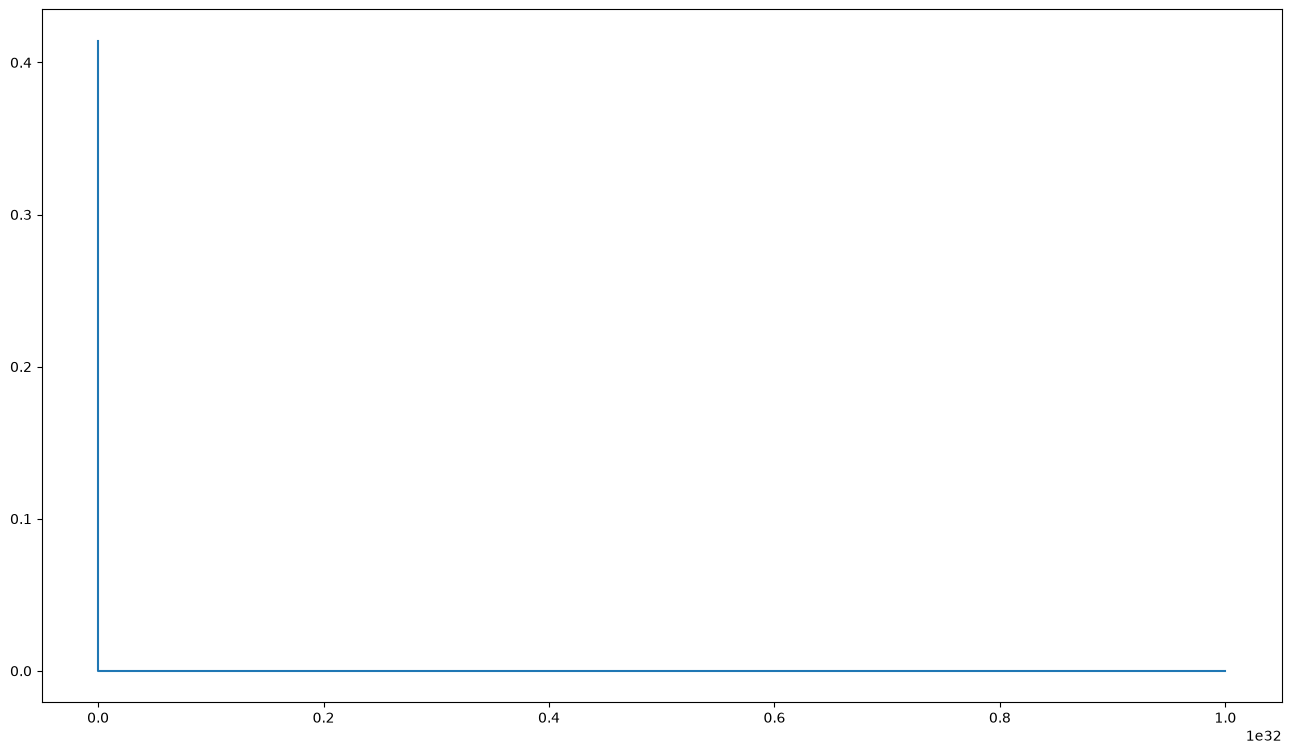

In [18]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.plot(xs, ys)
plt.show()

Conclusion: The value of the function is zero weh we plugin x big enough. This happens because when x is large we subtract to big numbers $\sqrt{x + 1}$ and $\sqrt{x}$. Since $x \to \infty$, these numbers are nearly equal. This leads the cancellation.

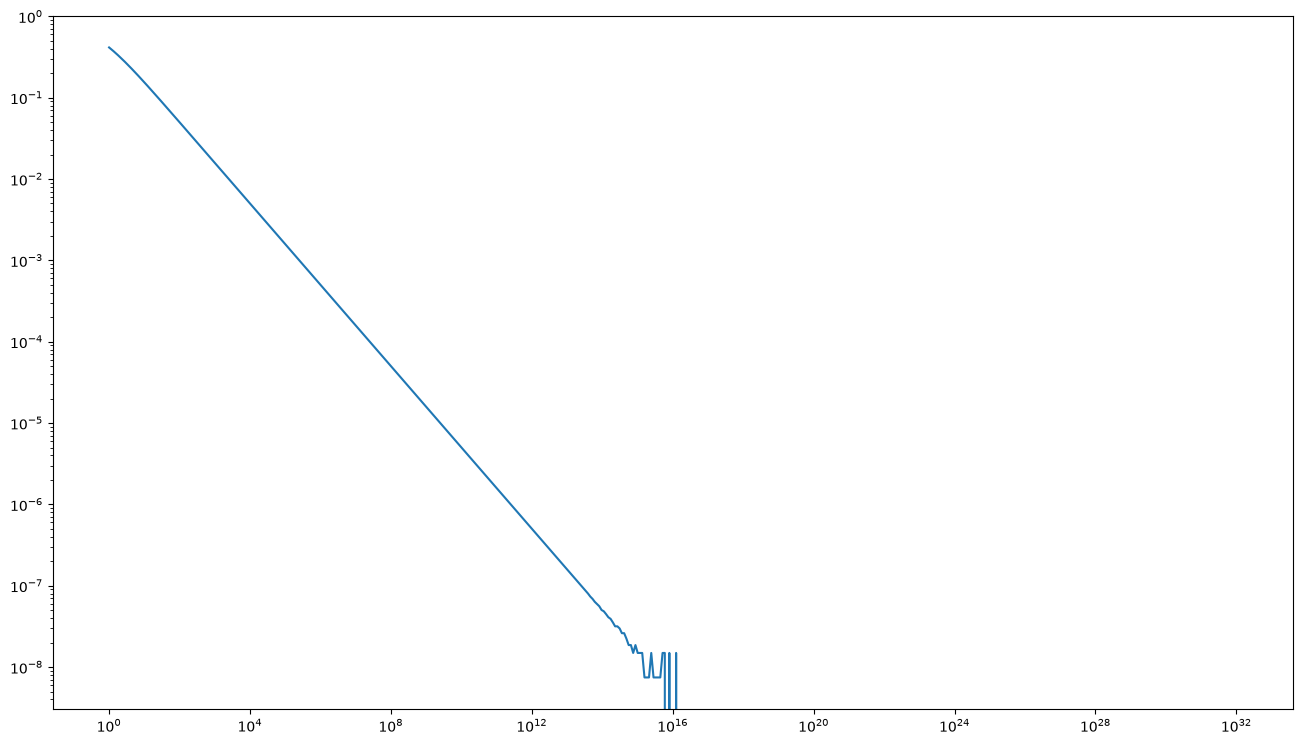

In [51]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.loglog(xs, ys)
plt.show()

In [29]:
# find the last index where $f(x)$ is not 0
for i, v in enumerate(ys):
    if v == 0:
        break
print(i - 1)
print(xs[i-1])
print(ys[i-1])

246
5964184945842435.0
1.4901161193847656e-08


How to avoid cancellation and compute the good values for $f(x)$?

We can use approximation of conjugate:

1) Conjugate
$$
f(x) = \sqrt{x+1} - \sqrt{x} = \frac{(\sqrt{x+1} - \sqrt{x})(\sqrt{x+1} + \sqrt{x})}{\sqrt{x+1} + \sqrt{x}}
2) = \frac{1}{\sqrt{x+1} + \sqrt{x}} \approx \frac{1}{2\sqrt{x}}
$$

In [36]:
# define two functions
def f_exact(x):
    return 1 / (math.sqrt(x + 1) + math.sqrt(x))

In [37]:
def f_approx(x):
    return 1/ (2 * math.sqrt(x))

In [38]:
# recalculate the ys using these two functions
ys_exact = [f_exact(x) for x in xs]
ys_approx = [f_approx(x) for x in xs]

In [39]:
# last 10 values
ys_exact[-10:]

[9.71733463268015e-17,
 9.025744396105587e-17,
 8.38337517263854e-17,
 7.786723864630707e-17,
 7.232536692608264e-17,
 6.717791451104158e-17,
 6.239681027356583e-17,
 5.795598092994453e-17,
 5.383120885227488e-17,
 5e-17]

In [40]:
ys_approx[-10:]

[9.71733463268015e-17,
 9.025744396105587e-17,
 8.38337517263854e-17,
 7.786723864630707e-17,
 7.232536692608264e-17,
 6.717791451104158e-17,
 6.239681027356583e-17,
 5.795598092994453e-17,
 5.383120885227488e-17,
 5e-17]

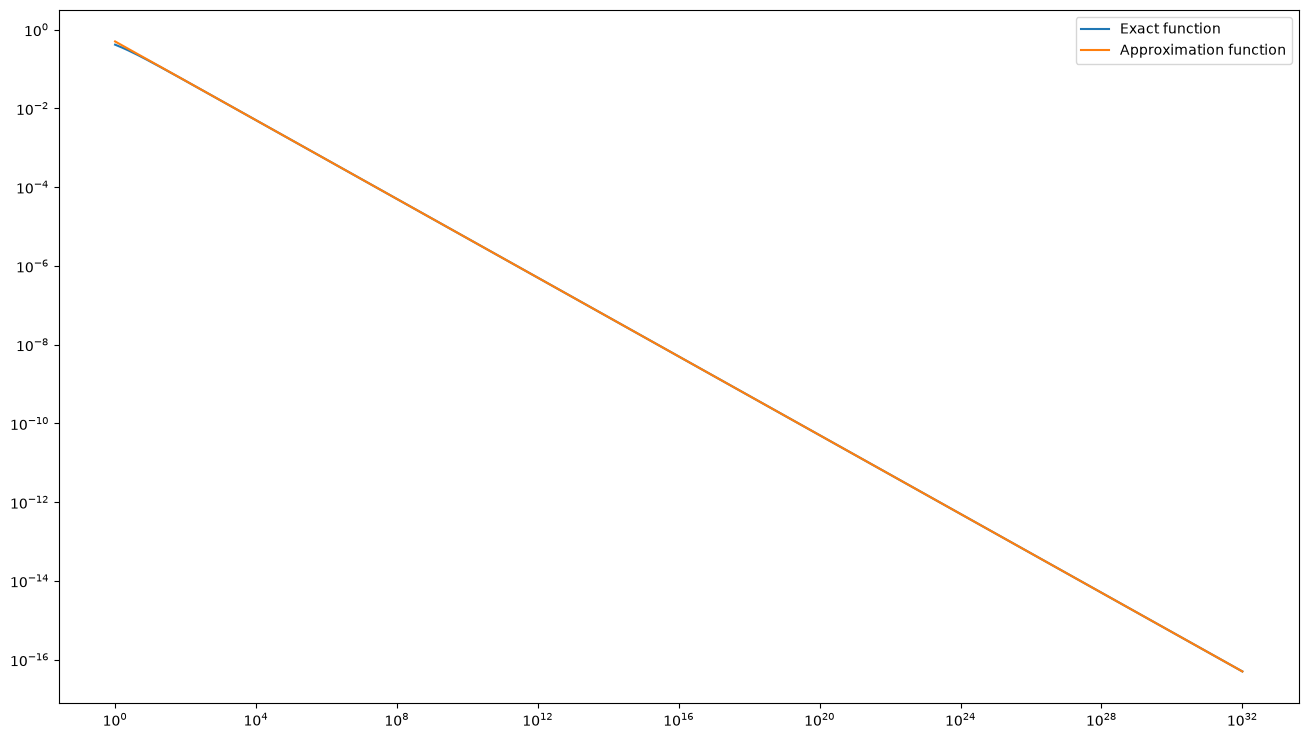

In [52]:
# plot these functions
fig, ax = plt.subplots(figsize=(16, 9))
ax.loglog(xs, ys_exact, label="Exact function")
ax.loglog(xs, ys_approx, label="Approximation function")

ax.legend()
plt.show()

So `f_exact` or `f_approx` are good functions to evaluate. In this loglog plot, we have
$$
y = \frac{1}{2\sqrt(x)}
$$
then
$$
\log(y) = \log(1/2) + \log(\frac{1}{\sqrt{x}}) = \log(1/2) - \frac{1}{2\log(x)}
$$
This explains the slope = 1/2 in the plot of these functions.

**Example:** Study the error analysis for the function
$$
f(x) = \frac{1-\cos(x)}{x^2}
$$
where $x$ is small.

1) Use the naive formula

In [53]:
# create values from 10^{-2} to 10^{-16}
xs = np.logspace(-2, -16, 500)

In [54]:
ys = [(1 - math.cos(x)) / (x**2) for x in xs]

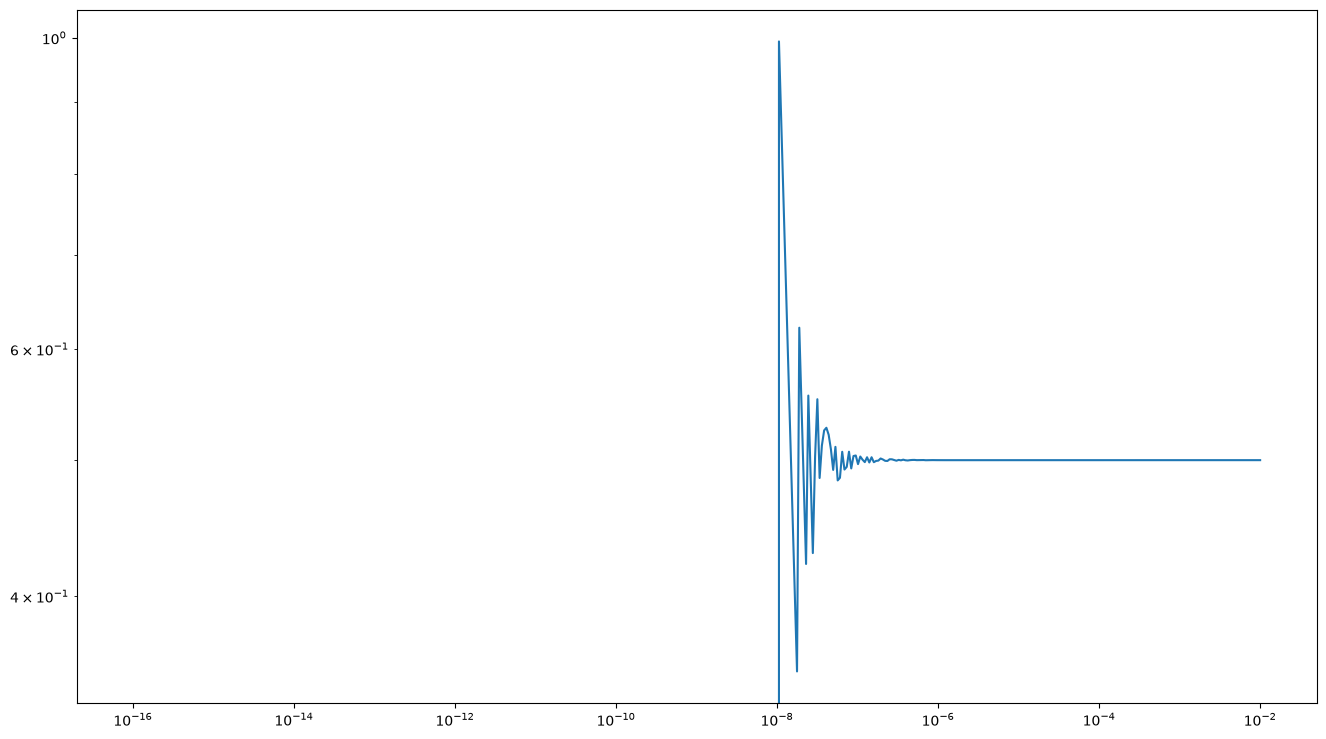

In [56]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.loglog(xs, ys)
plt.show()

How to avoid it?

Use the Taylor expansion.

In [57]:
from sympy import symbols, cos, series

In [58]:
x_var = symbols("x")

In [59]:
top = 1 - cos(x_var)

In [60]:
top_series = series(top, x_var, x0=0, n=8)

In [61]:
top_series

x**2/2 - x**4/24 + x**6/720 + O(x**8)

In [62]:
top_series / (x_var ** 2)

(x**2/2 - x**4/24 + x**6/720 + O(x**8))/x**2

In [63]:
from sympy import simplify

In [64]:
simplify(top_series / (x_var ** 2))

1/2 - x**2/24 + x**4/720 + O(x**6)

In [65]:
# define a better approximation
def f_approx(x):
    return 1/2 - x ** 2 / 24 + x ** 4 / 720

In [66]:
# recalculate the values of the function
ys_approx = [f_approx(x) for x in xs]

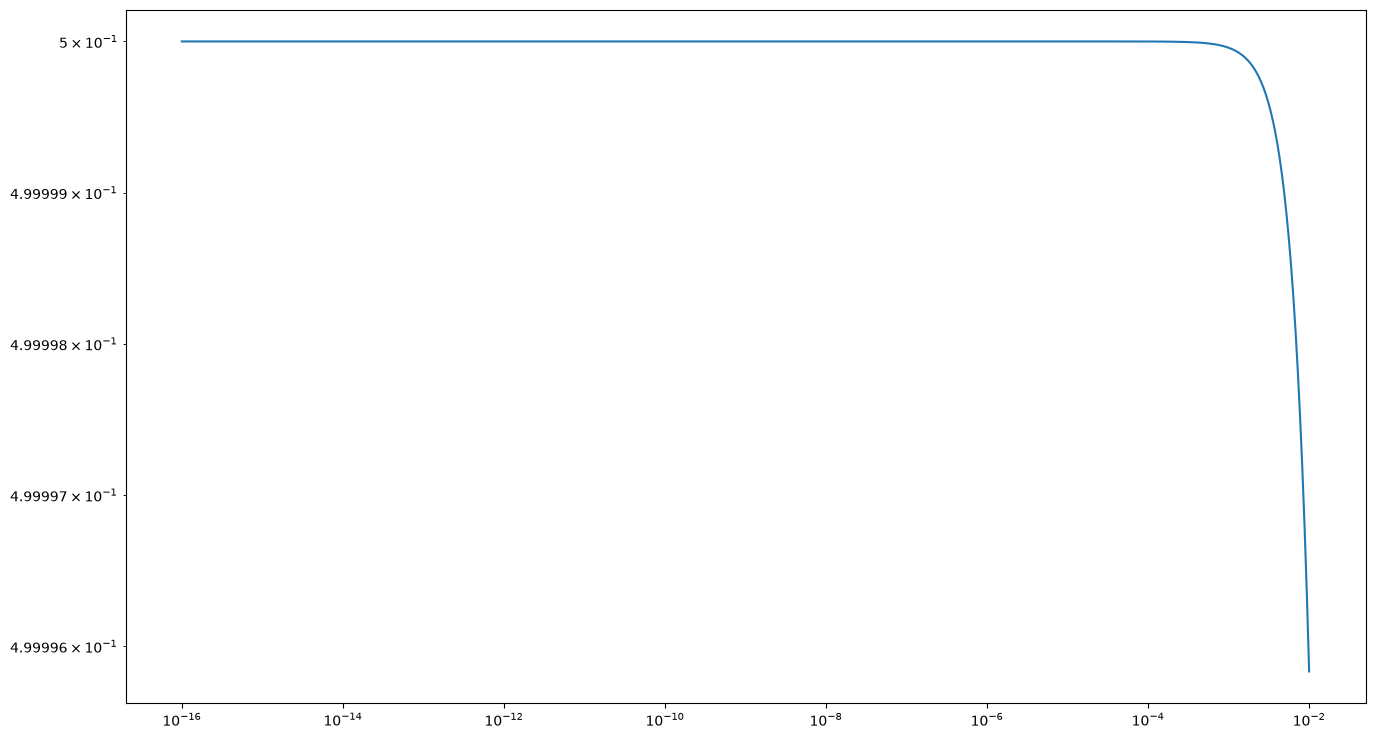

In [70]:
fig, ax = plt.subplots(figsize=(16, 9))
plt.loglog(xs, ys_approx)
plt.show()